# 作业2 （ridge+逻辑回归）
1013
- 使用 Python + NumPy，不直接调用 sklearn 逻辑回归模型，编程实现逻辑回归；
- 数据集：网上数据集或者自己构造数据集。
- 训练过程：
    - 绘制损失、模型参数随迭代次数的变化曲线；调学习率观察收敛变化；
    - 可视化：训练散点 + 分割界面（直线或平面）

***本实验实现二分类，利用直线分割界面***

## 实现思路：三步走（本 notebook 的来历）

本作业在上一份线性回归作业（完整代码见 `hw_02_iris_ridge_regression.ipynb`）的基础上**分三步演变**而来：

| 步骤 | 做了什么 | 模型与损失 | 对应课件 |
|---|---|---|---|
| **第一步：线性回归** | 编程实现解析解（单变量公式 3.7/3.8）与梯度下降（单变量 + 2变量矩阵形式） | f(x) = wᵀx；E = 1/2·Σ(f(xᵢ)−yᵢ)² | hw_01《第二章 线性模型》：单变量-解析解法 p14、单变量-梯度下降法 p20、多变量-解析解法 p39、多变量-梯度下降法 p40 |
| **第二步：+Ridge 二范数惩罚** | 损失加 λ‖w̃‖₂²（偏置 w₀ 不惩罚）；解析解正规方程加 λ·D；梯度下降加 λ·D·w 项 | E += (λ/2)·‖w̃‖₂² | part2《误差来源》p22-24、《ridge回归》p28 |
| **第三步：+sigmoid → 逻辑回归（本 notebook）** | 线性输出外套逻辑函数 g，平方损失换成交叉熵，实现二分类 | **f(x) = g(wᵀx) = 1/(1+e^(−wᵀx))**；E = 交叉熵 + Ridge 项 | part2《logistic回归》p30-46 |

三步**共用同一套记号与代码骨架**：w₀ = b、x₀ = 1（X 首列补 1）、D = diag(0,1,…,1) 使偏置不被惩罚、"唯一函数 + λ 可调"；每一步只在上一步基础上改少量代码（下方 markdown 按此脉络讲解）。

# 数据集

In [8]:
# 加载清洗数据集
import sys, pathlib
sys.path.append( str (pathlib.Path.cwd().parent))

from my_datasets.iris_utils import load_iris_ready
x_train, x_test, y_train, y_test, scaler = load_iris_ready() # 数据集处理单独封装，达到复用目的

display(x_train)
display(y_train)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
30,-1.192531,0.035465,-1.143600,-1.222275
31,-0.454691,0.701825,-1.201142,-0.959728
80,-0.331718,-1.519376,0.122339,-0.040816
88,-0.208745,-0.186656,0.294967,0.221730
55,-0.085771,-0.630896,0.525137,0.221730
...,...,...,...,...
102,1.635854,-0.186656,1.330734,1.271916
100,0.652068,0.479705,1.388277,1.797009
44,-0.823611,1.590305,-0.970972,-0.959728
132,0.775042,-0.630896,1.158106,1.403189


30         setosa
31         setosa
80     versicolor
88     versicolor
55     versicolor
          ...    
102     virginica
100     virginica
44         setosa
132     virginica
117     virginica
Name: species, Length: 119, dtype: str

# 数据准备：二分类标签（setosa vs 其他）

<img src="./第二章%20线性模型_part2_pages/logistic回归/page_045.png" width="48%">

课件 p45：鸢尾花数据集 150 条、4 特征、3 类各 50 条。按作业要求第一步只做**二分类**：

- **正例 y = 1：setosa**；**负例 y = 0：其余两类合并为"其他"**（多分类拆解法 OvO/OvR 见课件 p42-44，暂不实现）
- 特征沿用 2 个：petal length / petal width（已标准化），决策边界是一条直线，可视化方便
- 设计矩阵构造与第一步线性回归完全相同：给 X 首列补 1（x₀ = 1），偏置 b 记作 **w₀**（课件 p36：令 w = (b; w)、x = (1; x)，模型即可写成 f(x) = g(wᵀx)）
- 与第一步的唯一区别：标签 y 从"品种编号 0/1/2（回归目标）"换成"是否 setosa 的 0/1（分类目标）"；特征 X、X_test 与训练/测试划分（119/30）原样复用

In [9]:
# 逻辑回归数据准备：二分类标签 + 设计矩阵（沿用前面的构造方式）
import numpy as np
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）——供本节所有绘图使用
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号

X0 = x_train[['petal length (cm)', 'petal width (cm)']].to_numpy()   # (m,2)：两个特征（已标准化）
X = np.hstack([np.ones((len(X0), 1)), X0])                # (m,3)：首列补 1 即 x₀，w₀ 就是偏置 b（课件 p36）
y = (y_train == 'setosa').astype(int).to_numpy()          # 二分类标签：setosa=1（正例），其他=0（负例）
X_test = np.hstack([np.ones((len(y_test), 1)),            # 测试集设计矩阵（首列补 1，同训练集规则）
                    x_test[['petal length (cm)', 'petal width (cm)']].to_numpy()])
y_test_log = (y_test == 'setosa').astype(int).to_numpy()  # 测试集二分类标签，同规则
m, m_test = len(y), len(y_test_log)                        # 训练/测试样本数

print(f'训练集: m = {m}，其中 setosa(1) = {y.sum()}，其他(0) = {(y == 0).sum()}')
print(f'测试集: m = {m_test}，其中 setosa(1) = {y_test_log.sum()}，其他(0) = {(y_test_log == 0).sum()}')
print('X 形状 =', X.shape, '（列数 3 = 参数个数 w0, w1, w2）')

训练集: m = 119，其中 setosa(1) = 44，其他(0) = 75
测试集: m = 30，其中 setosa(1) = 6，其他(0) = 24
X 形状 = (119, 3) （列数 3 = 参数个数 w0, w1, w2）


## 模型与损失函数（逻辑函数 + 交叉熵 + Ridge 正则）

### 损失函数的三步演变（第一、二步的完整代码在 hw_02_iris_ridge_regression.ipynb）

**第一步：线性回归的平方损失**（hw_01《单变量-解析解法》p14，f(x) = w·x + b）：

<img src="../hw_01/第二章%20线性模型_pages/单变量-解析解法/page_014.png" width="46%">

　　E(w, b) = 1/2·Σ(f(xᵢ)−yᵢ)²，解析解为公式 (3.7)/(3.8)。但 p30-33 指出：**平方损失 + 阈值不适合分类**（离群点会把最小二乘直线拉偏）。

**第二步：+Ridge 二范数惩罚**（part2《误差来源》p24，方差大/过拟合时的对策）：

<img src="./第二章%20线性模型_part2_pages/误差来源/page_024.png" width="42%">

　　E(w, b) = 1/(2m)·[ Σ(f(xᵢ)−yᵢ)² + λ·‖w‖₂² ]（**偏置 b 不惩罚**）。

**第三步：+sigmoid → 逻辑回归（本 notebook 最终形态）**：把线性输出 wᵀx 外套逻辑函数 g 压成概率，损失由极大似然导出为交叉熵：

<img src="./第二章%20线性模型_part2_pages/logistic回归/page_034.png" width="42%">　<img src="./第二章%20线性模型_part2_pages/logistic回归/page_037.png" width="42%">

**模型（课件 p35/p40）：f(x) = g(wᵀx) = 1/(1+e^(−wᵀx))**，g 为 sigmoid（逻辑）函数，g′(z) = g(z)(1−g(z))；
f 的含义是概率 p(y=1|x)，**f ≥ 0.5 ⇔ wᵀx ≥ 0 判为 1**（课件 p31/p35，wᵀx = 0 就是决策边界）。

**交叉熵损失（课件 p36-37/p40）**：由极大似然 L(w) = ∏f^yⁱ(1−f)^(1−yⁱ) 取负——
**E(w) = −Σ[ yᵢ·ln f(xᵢ) + (1−yᵢ)·ln(1−f(xᵢ)) ]**，即 Cost = −ln f（y=1）、−ln(1−f)（y=0）。

<span style="color:red">**Ridge 正则（第二步的二范数惩罚原样保留，课件 p41）**：E(w) 再加 **(λ/2)·Σⱼ≥1 wⱼ²**，**w₀ 即偏置 b 不惩罚**</span>（D = diag(0,1,1)）。

**梯度（课件 p38/p40，利用 g′ = g(1−g) 化简）**：∂E/∂w₀ = Σ(f(xᵢ)−yᵢ)；**∂E/∂wⱼ = Σ(f(xᵢ)−yᵢ)·xᵢⱼ + λ·wⱼ**（j≥1）——与线性回归形式完全相同（p40 对照结论）。
交叉熵损失**没有解析解**（p39：w* = argmin E 只能用梯度下降求数值解），下面先实现函数再扫描 λ。

In [10]:
# 逻辑回归核心函数：sigmoid、交叉熵损失、准确率、批量梯度下降（唯一函数，λ 可调）
def sigmoid(z):
    """逻辑（sigmoid）函数 g(z) = 1/(1+e^(-z))，把线性输出 w·x 压缩到 (0,1) 当概率（课件 p34）"""
    return 1.0 / (1.0 + np.exp(-z))

D_log = np.eye(3); D_log[0, 0] = 0.0                       # D=diag(0,1,1)：正则惩罚跳过 w0（偏置 b 不惩罚，课件 p41）

def E_logistic(w, X, y, lam=0.0):
    """交叉熵损失 E = Σ Cost + (λ/2)·Σ(j≥1) wⱼ²（课件 p37 + p41）"""
    f = sigmoid(X @ w)                                     # 当前模型输出（概率）
    f = np.clip(f, 1e-12, 1 - 1e-12)                       # 数值保护：log(0) 会溢出
    ce = -np.sum(y * np.log(f) + (1 - y) * np.log(1 - f))  # 交叉熵（课件 p37）
    return ce + lam / 2 * np.sum(w[1:] ** 2)               # Ridge：λ/2·‖w₁₋‖²（w0 不惩罚）

def accuracy(w, Xa, ya):
    """分类准确率：f ≥ 0.5 判为 1（等价 w·x ≥ 0，课件 p31/p35 决策边界）"""
    return np.mean((sigmoid(Xa @ w) >= 0.5) == (ya == 1))

def gradient_descent_logistic(X, y, lr, lam, max_iter=20000, tol=1e-10, w=None):
    """批量梯度下降求 Ridge 逻辑回归（课件 p39/p40 更新式 + p41 正则项；唯一的逻辑回归函数，λ 可调）

    返回: (w, history)；history 每行 [损失E, w0, w1, w2]，供绘制损失/参数变化曲线"""
    w = np.zeros(X.shape[1]) if w is None else w.copy()    # 起始点：零向量
    history = [(E_logistic(w, X, y, lam), *w)]             # 记录初始状态 [E, w0, w1, w2]
    for _ in range(max_iter):
        f = sigmoid(X @ w)                                 # 预测概率 f(x)=g(w·x)（与线性回归唯一不同处）
        w = w - lr * (X.T @ (f - y) + lam * (D_log @ w))   # 更新式：p40 梯度 + p41 ridge 项 λ·D·w
        history.append((E_logistic(w, X, y, lam), *w))     # 记录 [E, w0, w1, w2]
        if abs(history[-2][0] - history[-1][0]) < tol:     # 损失几乎不再下降 → 停止
            break
    return w, np.array(history)

# ---------- λ 扫描：同一个函数只调 λ（α 固定 0.001；λ=0 行即课件 p40 普通逻辑回归，作对照） ----------
print('λ 扫描（α=0.001，λ=0 即课件 p40 普通逻辑回归作对照）：')
for lam in [0, 0.5, 1, 2, 5, 10]:
    w_s, h_s = gradient_descent_logistic(X, y, lr=0.001, lam=lam)
    a_tr = accuracy(w_s, X, y)                             # 训练准确率
    a_te = accuracy(w_s, X_test, y_test_log)               # 测试准确率
    note = '（未收敛打满迭代！setosa 线性可分 → 交叉熵最优解 w→∞）' if len(h_s) >= 20000 else ''
    print(f'λ={lam:<5} iters={len(h_s)-1:<6} E={h_s[-1, 0]:9.4f}  acc_train={a_tr:.3f}  acc_test={a_te:.3f}  ‖w₁₋‖₂={np.linalg.norm(w_s[1:]):.4f} {note}')

# 选定默认正则强度：λ=0 不收敛（可分数据下 w 一直增大、无有限最优解），λ=1 收敛快、参数明显收缩、准确率 100%
LAMBDA_LOG = 1.0                                          # 默认 λ（λ=0 对照见上）
print(f'\n选定 LAMBDA_LOG = {LAMBDA_LOG}（原因：λ=0 无有限最优解、打满迭代；λ≥0.5 均收敛且 acc=100%）')

λ 扫描（α=0.001，λ=0 即课件 p40 普通逻辑回归作对照）：
λ=0     iters=20000  E=   0.1610  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=7.4704 （未收敛打满迭代！setosa 线性可分 → 交叉熵最优解 w→∞）
λ=0.5   iters=10874  E=   5.9021  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=3.7820 
λ=1     iters=6011   E=   8.8898  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=3.1983 
λ=2     iters=3347   E=  13.0901  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=2.6594 
λ=5     iters=1633   E=  20.9541  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=2.0153 
λ=10    iters=1032   E=  28.8144  acc_train=1.000  acc_test=1.000  ‖w₁₋‖₂=1.5797 

选定 LAMBDA_LOG = 1.0（原因：λ=0 无有限最优解、打满迭代；λ≥0.5 均收敛且 acc=100%）


## 梯度下降法

### 更新式的三步演变（每一步只多加一点点）

**第一步：线性回归的梯度下降**（hw_01《单变量-梯度下降法》p20）：

<img src="../hw_01/第二章%20线性模型_pages/单变量-梯度下降法/page_020.png" width="46%">

　　w := w − α·Σ(f(xᵢ)−yᵢ)·xᵢ　；　b := b − α·Σ(f(xᵢ)−yᵢ)（两个偏导数 + 循环与停止阈值）。

**第二步：+Ridge**（part2《ridge回归》p28，红圈 λωⱼ 项）：

<img src="./第二章%20线性模型_part2_pages/ridge回归/page_028.png" width="46%">

　　梯度多加二范数项 **λ·wⱼ**（向量形式 λ·D·w，**D 使偏置 w₀ 不被收缩**）。

**第三步：+sigmoid → 逻辑回归（本 notebook）**：预测 f 从 wᵀx 换成 g(wᵀx)，梯度形式不变（p40 左右对照）：

<img src="./第二章%20线性模型_part2_pages/logistic回归/page_038.png" width="42%">　<img src="./第二章%20线性模型_part2_pages/logistic回归/page_040.png" width="42%">

**更新式（向量形式，w₀..w₂ 一次同步更新）**：

　　**w := w − α·[ Xᵀ(f − y) + λ·D·w ]**，其中 f = g(Xw)、D = diag(0,1,1)

对照线性回归的更新式 w := w − α·[Xᵀ(Xw−y) + λ·D·w]：<span style="color:red">**只把预测 Xw 换成 g(Xw)，其余完全一致**</span>（p40 左右对照的核心结论）。实现时更新逻辑写在 gradient_descent_logistic 中（上一单元格），本单元格设定超参数并训练。

In [11]:
# 逻辑回归梯度下降：单次训练（复用 gradient_descent_logistic）
LEARNING_RATE_LOG = 0.002    # 学习率 α（实验：0.0002~0.05 均稳定收敛，取中档）
MAX_ITERS_LOG    = 20000     # 最大迭代次数（λ=0 时不收敛会打满，见 λ 扫描输出）
TOL_LOG          = 1e-10     # 停止阈值：相邻两次损失变化 < TOL 即认为收敛

w_log, log_hist = gradient_descent_logistic(X, y, lr=LEARNING_RATE_LOG, lam=LAMBDA_LOG,
                                            max_iter=MAX_ITERS_LOG, tol=TOL_LOG)

print(f'迭代次数      = {len(log_hist) - 1}')
print(f'逻辑回归 w    = {w_log.round(6)}   （w0 即偏置 b，负值表示 petal 越小越可能是 setosa）')
print(f'最终损失 E    = {log_hist[-1, 0]:.6f}（交叉熵 + λ/2·‖w₁₋‖²）')
print(f'训练准确率    = {accuracy(w_log, X, y):.3f}')
print(f'测试准确率    = {accuracy(w_log, X_test, y_test_log):.3f}')

迭代次数      = 3168
逻辑回归 w    = [-2.158592 -2.433227 -2.075704]   （w0 即偏置 b，负值表示 petal 越小越可能是 setosa）
最终损失 E    = 8.889826（交叉熵 + λ/2·‖w₁₋‖²）
训练准确率    = 1.000
测试准确率    = 1.000


### 绘制损失、模型参数随迭代次数的变化曲线

封装成函数 plot_gd_curves_n（支持对比多组训练结果）；history 每行 [损失E, w0, w1, w2]。
逻辑回归无解析解，故不画 w* 对照虚线。

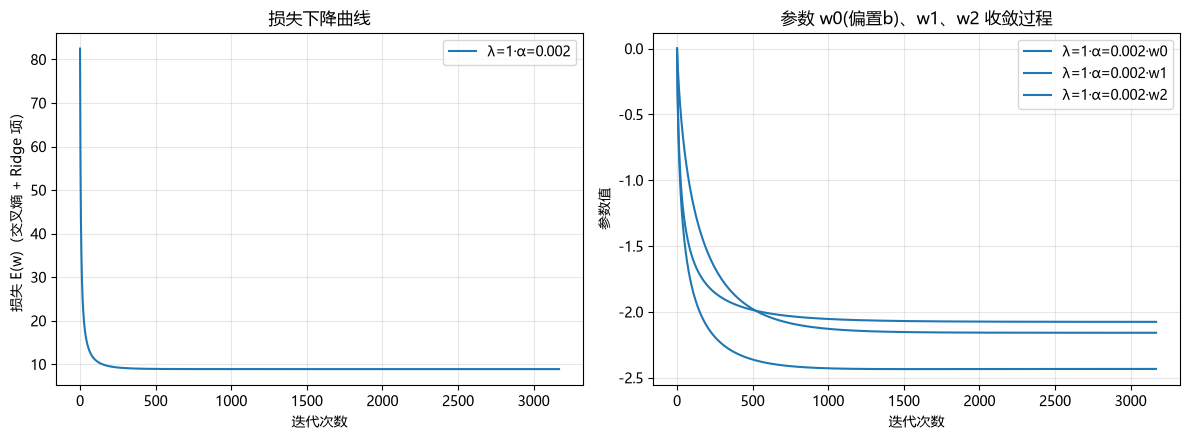

In [12]:
def plot_gd_curves_n(histories, labels, w_star=None):
    """绘制梯度下降的损失下降曲线与各参数收敛曲线。

    参数:
        histories: list，训练记录（gradient_descent_logistic 返回的 history，
                   每行 [损失E, w0, w1, …, wn]）
        labels:    list，与 histories 一一对应的标签
        w_star:    可选，对照参数向量，用于画参考虚线
    """
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))          # fig 用不到，用 _ 接包
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']  # 每组曲线的配色（zip 按位置取色，最多同时对比 5 组）

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        for j in range(h.shape[1] - 1):                   # 逐个参数画收敛曲线
            ax2.plot(iters, h[:, j + 1], color=c, label=f'{lab}·w{j}')

    if w_star is not None:                                # 解析解对照（虚线）
        for j, ws in enumerate(np.atleast_1d(w_star)):
            ax2.axhline(ws, color='gray', ls=':', lw=1.2, label=f'参考 w{j}*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w)（交叉熵 + Ridge 项）')
    ax1.set_title('损失下降曲线')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数 w0(偏置b)、w1、w2 收敛过程')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# 绘制逻辑回归训练曲线（单次结果）
plot_gd_curves_n([log_hist], [f'λ={LAMBDA_LOG:g}·α={LEARNING_RATE_LOG}'])

### 调学习率观察收敛变化

对比 3 组学习率 α（λ 固定为 LAMBDA_LOG，均走同一个 gradient_descent_logistic 函数）：
α 越大收敛越快；交叉熵损失不像平方损失那样剧烈震荡，实验范围内（≤0.05）均稳定收敛。

=== α = 0.0005 ===
迭代次数   = 11368
逻辑回归 w = [-2.158534 -2.433343 -2.075533]
最终损失 E = 8.889826
测试准确率 = 1.000



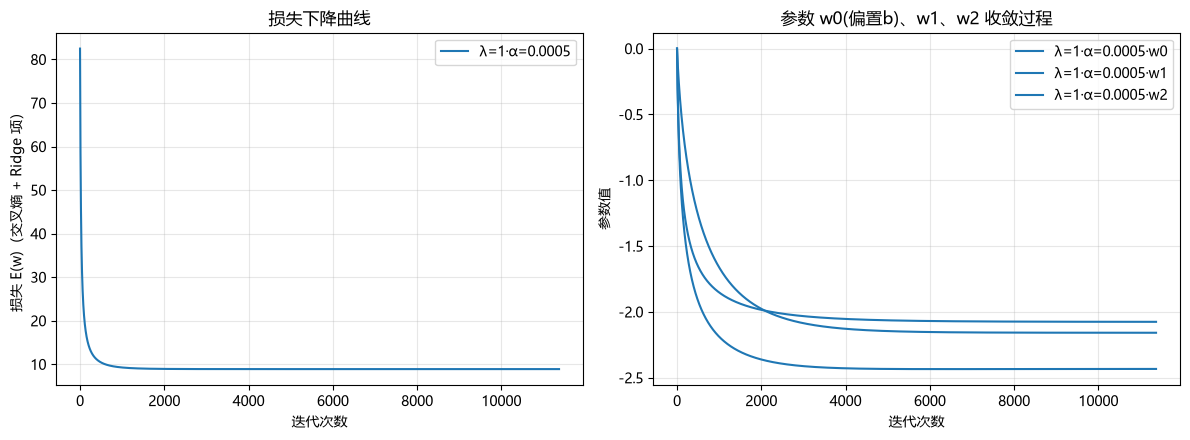

=== α = 0.002 ===
迭代次数   = 3168
逻辑回归 w = [-2.158592 -2.433227 -2.075704]
最终损失 E = 8.889826
测试准确率 = 1.000



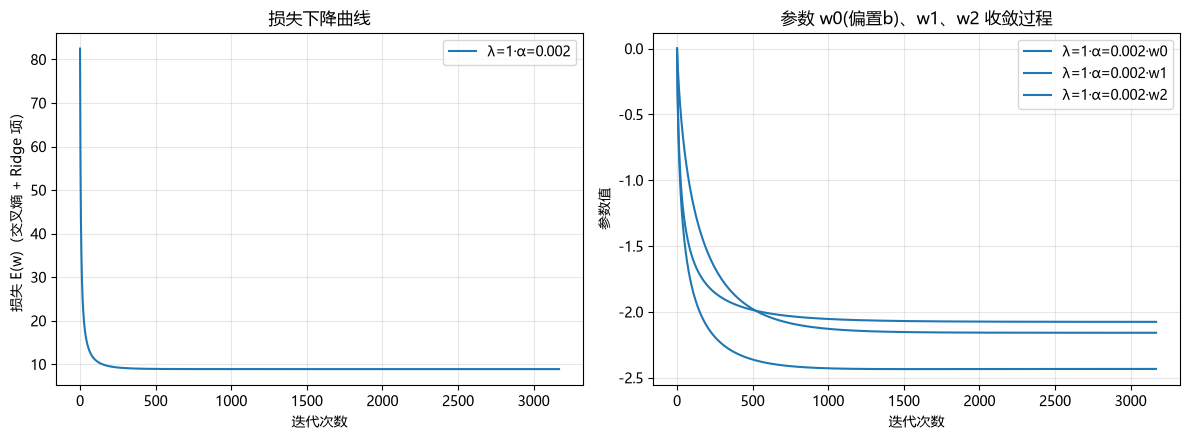

=== α = 0.01 ===
迭代次数   = 703
逻辑回归 w = [-2.158618 -2.433158 -2.075799]
最终损失 E = 8.889826
测试准确率 = 1.000



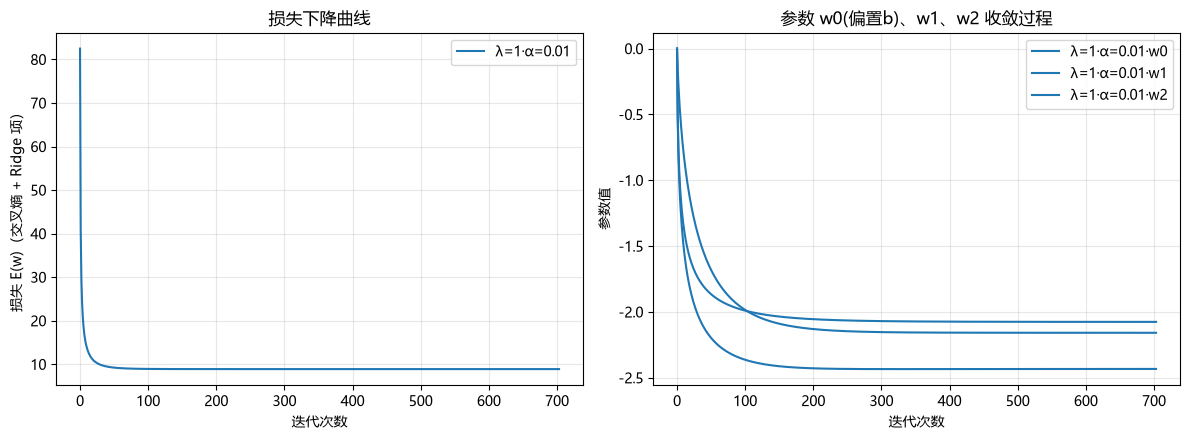

In [13]:
# 调学习率观察收敛变化：对比 3 组不同学习率 α，分三次训练并分别输出
learning_rates_log = [0.0005, 0.002, 0.01]

for lr in learning_rates_log:
    # ---- 训练一组学习率 ----
    w_lr, h_lr = gradient_descent_logistic(X, y, lr=lr, lam=LAMBDA_LOG,
                                           max_iter=MAX_ITERS_LOG, tol=TOL_LOG)

    # ---- 打印该组结果 ----
    print(f'=== α = {lr} ===')
    print(f'迭代次数   = {len(h_lr) - 1}')
    print(f'逻辑回归 w = {w_lr.round(6)}')
    print(f'最终损失 E = {h_lr[-1, 0]:.6f}')
    print(f'测试准确率 = {accuracy(w_lr, X_test, y_test_log):.3f}\n')

    # ---- 单独绘制该组的损失/参数收敛曲线（分三次输出） ----
    plot_gd_curves_n([h_lr], [f'λ={LAMBDA_LOG:g}·α={lr}'])

### 可视化：训练散点 + 分割直线

决策边界：**f(x) = 0.5 ⇔ wᵀx = 0**（课件 p35），在两个特征平面上是一条直线
w₀ + w₁·x₁ + w₂·x₂ = 0，即 x₂ = −(w₀ + w₁·x₁)/w₂；直线一侧判 setosa(1)，另一侧判其他(0)。

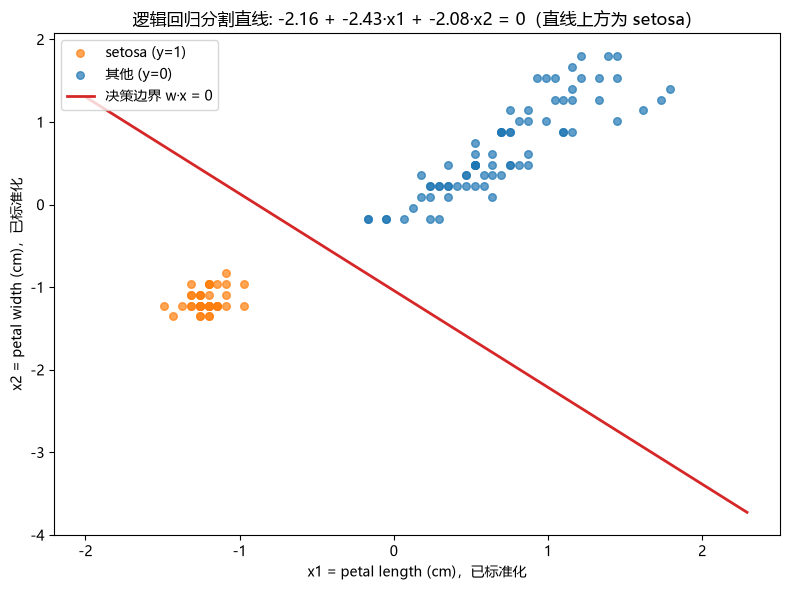

训练准确率 = 1.000，测试准确率 = 1.000
说明：setosa 在两特征平面上线性可分，边界把两类完全分开；多分类（OvR）见课件 p42-44，暂不实现


In [14]:
# 可视化：训练散点 + 逻辑回归分割直线（在 2 特征平面上画 w·x = 0 边界）
g1 = np.linspace(X0[:, 0].min() - 0.5, X0[:, 0].max() + 0.5, 100)   # x1（花瓣长）取值范围
g2 = -(w_log[0] + w_log[1] * g1) / w_log[2]                          # 决策边界 x2 = −(w0+w1·x1)/w2

plt.figure(figsize=(8, 6))
plt.scatter(X0[y == 1, 0], X0[y == 1, 1], s=30, alpha=0.7,
            color='tab:orange', label='setosa (y=1)')                # 正例散点
plt.scatter(X0[y == 0, 0], X0[y == 0, 1], s=30, alpha=0.7,
            color='tab:blue', label='其他 (y=0)')                     # 负例散点
plt.plot(g1, g2, color='tab:red', lw=2, label='决策边界 w·x = 0')      # 分割直线
plt.xlabel('x1 = petal length (cm)，已标准化')
plt.ylabel('x2 = petal width (cm)，已标准化')
plt.title(f'逻辑回归分割直线: {w_log[0]:.2f} + {w_log[1]:.2f}·x1 + {w_log[2]:.2f}·x2 = 0（直线上方为 setosa）')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f'训练准确率 = {accuracy(w_log, X, y):.3f}，测试准确率 = {accuracy(w_log, X_test, y_test_log):.3f}')
print('说明：setosa 在两特征平面上线性可分，边界把两类完全分开；多分类（OvR）见课件 p42-44，暂不实现')